<a href="https://colab.research.google.com/github/bigbrowniebael/Python-Data-Analysis-Portfolio/blob/main/Movie_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

The goal of this project is to find out the highest earning genre for films and to showcase my ability to clean and explore data.

In [ ]:
from google.colab import files
uploaded = files.upload()

import numpy as np
import pandas as pd

df = pd.read_csv('tmdb_5000_movies.csv')
df.head()

Saving tmdb_5000_movies.csv to tmdb_5000_movies.csv


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-03-07,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124


In [ ]:
df.info()
df.isnull().sum()
df.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   object 
 2   homepage              1712 non-null   object 
 3   id                    4803 non-null   int64  
 4   keywords              4803 non-null   object 
 5   original_language     4803 non-null   object 
 6   original_title        4803 non-null   object 
 7   overview              4800 non-null   object 
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   object 
 10  production_countries  4803 non-null   object 
 11  release_date          4802 non-null   object 
 12  revenue               4803 non-null   int64  
 13  runtime               4801 non-null   float64
 14  spoken_languages      4803 non-null   object 
 15  status               

0

In [ ]:
# Remove irrelevant columns
df = df.drop(['homepage', 'status', 'tagline','id', 'production_countries', 'production_companies','keywords', 'overview', 'original_language'], axis=1)

# Remove rows with missing 'budget' or 'revenue'
df = df.dropna(subset=['budget', 'revenue'])

# Convert 'release_date' to datetime
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')

# Make float values more digestible
pd.options.display.float_format = '{:,.0f}'.format


# Calculate profit and create a profit column
df['profit'] = df['revenue'] - df['budget']
df['profit_pretty'] = df['profit'].apply(lambda x: f"{x:,.0f}")

In [ ]:
df.info()
df.isnull().sum()
df.head(10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   budget            4803 non-null   int64         
 1   genres            4803 non-null   object        
 2   original_title    4803 non-null   object        
 3   popularity        4803 non-null   float64       
 4   release_date      4802 non-null   datetime64[ns]
 5   revenue           4803 non-null   int64         
 6   runtime           4801 non-null   float64       
 7   spoken_languages  4803 non-null   object        
 8   title             4803 non-null   object        
 9   vote_average      4803 non-null   float64       
 10  vote_count        4803 non-null   int64         
 11  profit            4803 non-null   int64         
 12  profit_pretty     4803 non-null   object        
dtypes: datetime64[ns](1), float64(3), int64(4), object(5)
memory usage: 487.9+ KB


,budget,genres,original_title,popularity,release_date,revenue,runtime,spoken_languages,title,vote_average,vote_count,profit,profit_pretty
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",Avatar,150,2009-12-10,2787965087,162,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Avatar,7,11800,2550965087,"2,550,965,087"
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",Pirates of the Caribbean: At World's End,139,2007-05-19,961000000,169,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Pirates of the Caribbean: At World's End,7,4500,661000000,"661,000,000"
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",Spectre,107,2015-10-26,880674609,148,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Spectre,6,4466,635674609,"635,674,609"
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",The Dark Knight Rises,112,2012-07-16,1084939099,165,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",The Dark Knight Rises,8,9106,834939099,"834,939,099"
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",John Carter,44,2012-03-07,284139100,132,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",John Carter,6,2124,24139100,"24,139,100"
5,258000000,"[{""id"": 14, ""name"": ""Fantasy""}, {""id"": 28, ""na...",Spider-Man 3,116,2007-05-01,890871626,139,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Spider-Man 3,6,3576,632871626,"632,871,626"
6,260000000,"[{""id"": 16, ""name"": ""Animation""}, {""id"": 10751...",Tangled,49,2010-11-24,591794936,100,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Tangled,7,3330,331794936,"331,794,936"
7,280000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",Avengers: Age of Ultron,134,2015-04-22,1405403694,141,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Avengers: Age of Ultron,7,6767,1125403694,"1,125,403,694"
8,250000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",Harry Potter and the Half-Blood Prince,99,2009-07-07,933959197,153,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Harry Potter and the Half-Blood Prince,7,5293,683959197,"683,959,197"
9,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",Batman v Superman: Dawn of Justice,156,2016-03-23,873260194,151,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Batman v Superman: Dawn of Justice,6,7004,623260194,"623,260,194"


In [ ]:
# The goal now, is to show the most popular genres by revenue as revenue is indicative of how many people spent money for the movie

import ast

# Currently, the genre column values are very hectic, and need to be separated
# Convert the 'genres' column from string representation of a list of dictionaries to an actual list of dictionaries
df['genres'] = df['genres'].apply(ast.literal_eval)

# Now, extract the 'name' from each dictionary in the list
df['genres'] = df['genres'].apply(lambda x: [genre['name'] for genre in x])

# Explode the list of genres into separate rows
df_exploded = df.explode('genres')

# Clean up extra spaces, just in case
df_exploded['genres'] = df_exploded['genres'].str.strip()

# Display the exploded DataFrame to see the results
print(df_exploded.head())

      budget           genres                            original_title  \
0  237000000           Action                                    Avatar   
0  237000000        Adventure                                    Avatar   
0  237000000          Fantasy                                    Avatar   
0  237000000  Science Fiction                                    Avatar   
1  300000000        Adventure  Pirates of the Caribbean: At World's End   

   popularity release_date     revenue  runtime  \
0         150   2009-12-10  2787965087      162   
0         150   2009-12-10  2787965087      162   
0         150   2009-12-10  2787965087      162   
0         150   2009-12-10  2787965087      162   
1         139   2007-05-19   961000000      169   

                                    spoken_languages  \
0  [{"iso_639_1": "en", "name": "English"}, {"iso...   
0  [{"iso_639_1": "en", "name": "English"}, {"iso...   
0  [{"iso_639_1": "en", "name": "English"}, {"iso...   
0  [{"iso_639_1": 

In [ ]:
# Group by genre and sum the revenue
genre_revenue = df_exploded.groupby('genres')['revenue'].sum().reset_index()

# Sort by revenue to get the most profitable genres
genre_revenue = genre_revenue.sort_values(by='revenue', ascending=False)

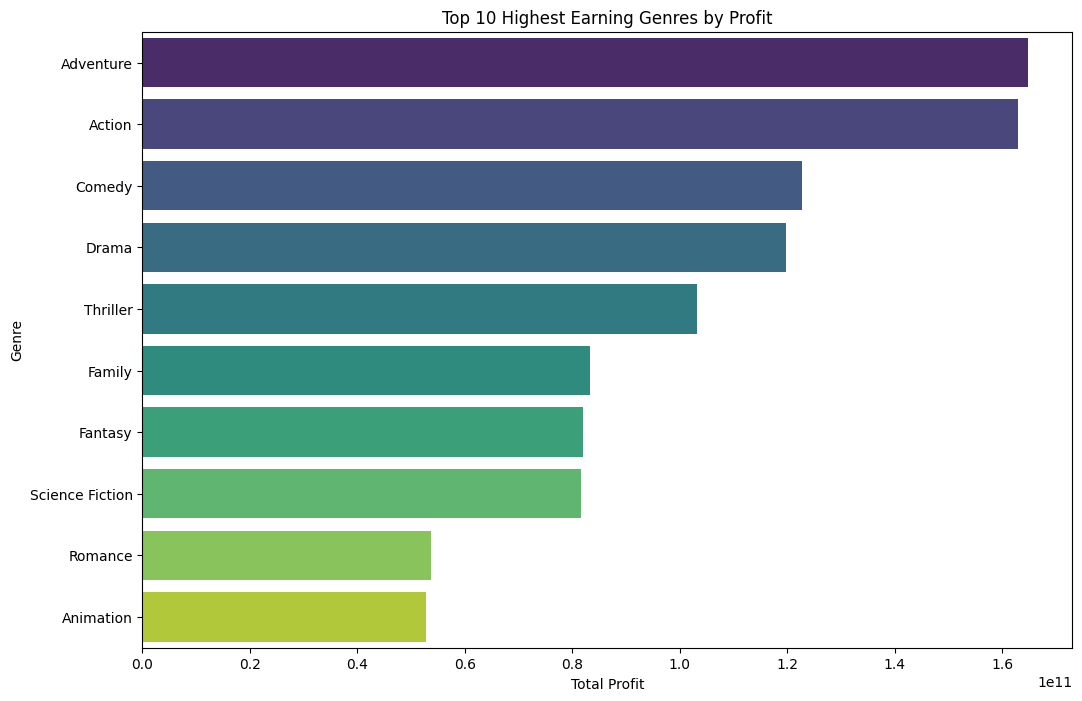

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select the top 10 highest-earning genres
top_10_genres = genre_revenue.head(10)

# Plot the top 10 genres by profit
plt.figure(figsize=(12, 8))
sns.barplot(x='revenue', y='genres', data=top_10_genres, palette='viridis', hue='genres')

# Add titles and labels
plt.title('Top 10 Highest Earning Genres by Profit')
plt.xlabel('Total Profit')
plt.ylabel('Genre')
plt.show()

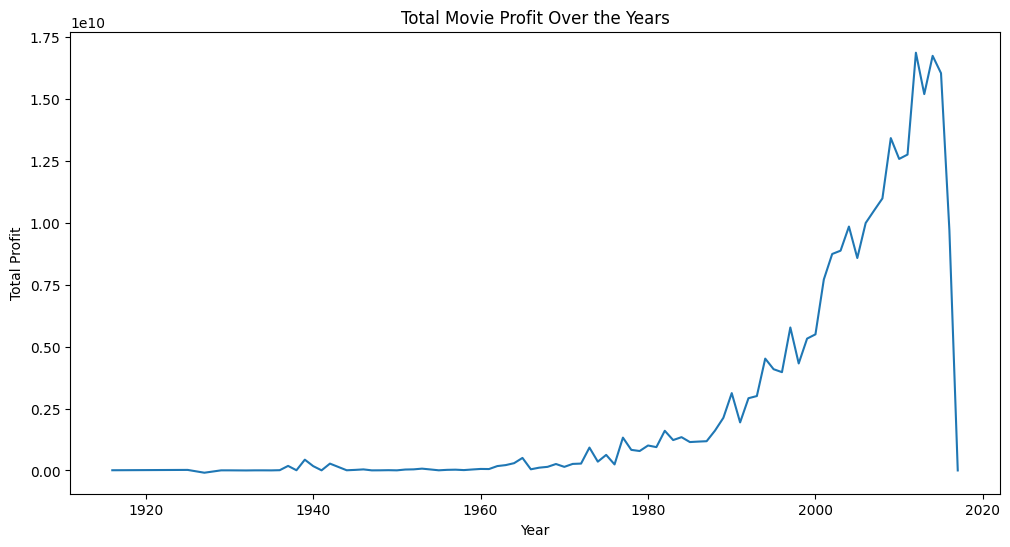

In [ ]:
df['release_year'] = df['release_date'].dt.year
profits_by_year = df.groupby('release_year')['profit'].sum().reset_index()

plt.figure(figsize=(12,6))
sns.lineplot(data=profits_by_year, x='release_year', y='profit')
plt.title('Total Movie Profit Over the Years')
plt.ylabel('Total Profit')
plt.xlabel('Year')
plt.show()

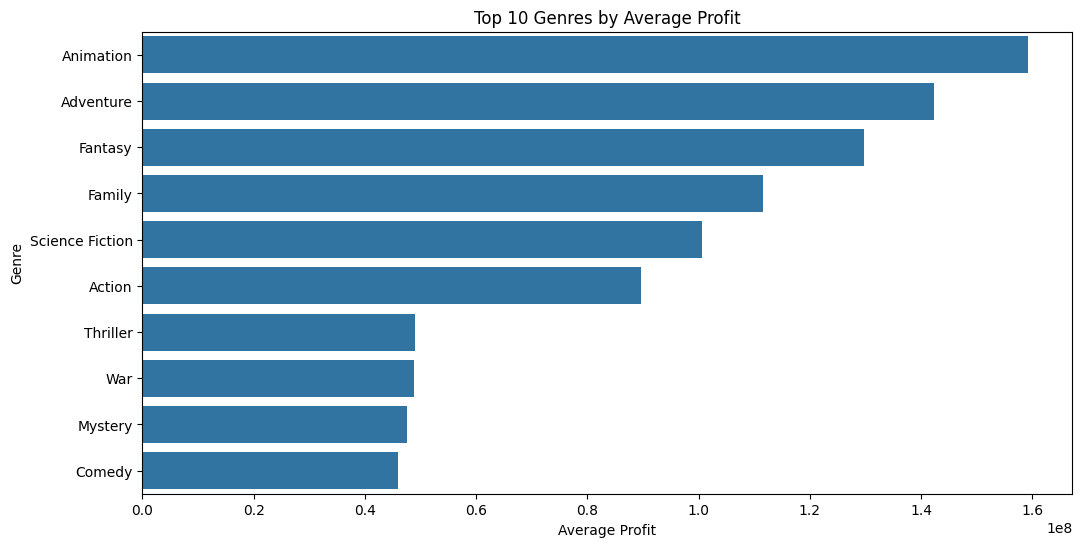

In [ ]:
avg_profit_by_genre = df.explode('genres').groupby('genres')['profit'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(12,6))
sns.barplot(x=avg_profit_by_genre.values, y=avg_profit_by_genre.index)
plt.title('Top 10 Genres by Average Profit')
plt.xlabel('Average Profit')
plt.ylabel('Genre')
plt.show()

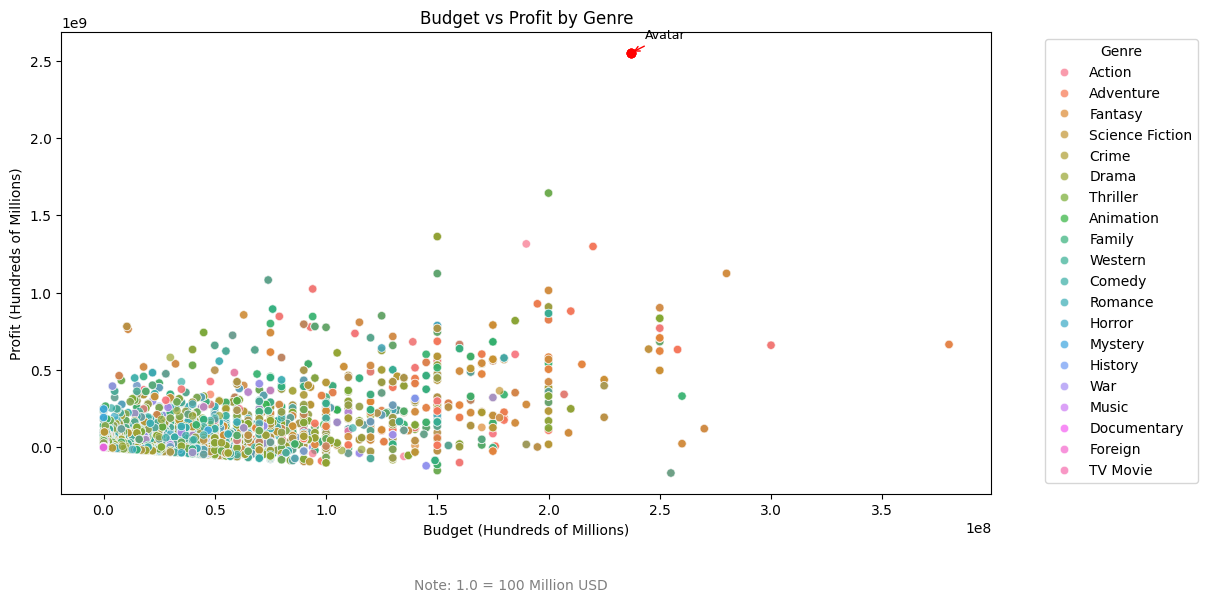

In [ ]:
exploded_df = df.explode('genres')

plt.figure(figsize=(12,6))
ax = sns.scatterplot(data=exploded_df, x='budget', y='profit', hue='genres', alpha=0.7)

# Find the outlier
outlier = exploded_df.loc[exploded_df['profit'].idxmax()]
plt.scatter(outlier['budget'], outlier['profit'], color='red')

# Annotate the outlier
ax.annotate(
    outlier['title'].iloc[0],
    (outlier['budget'].to_numpy()[0], outlier['profit'].to_numpy()[0]),
    xytext=(10, 10),
    textcoords='offset points',
    arrowprops=dict(arrowstyle='->', color='red'),
    fontsize=9,
    color='black'
)

plt.title('Budget vs Profit by Genre')
plt.xlabel('Budget (Hundreds of Millions)')
plt.ylabel('Profit (Hundreds of Millions)')
plt.legend(title='Genre', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.figtext(0.5, -0.05, 'Note: 1.0 = 100 Million USD', ha='center', fontsize=10, color='gray')
plt.show()

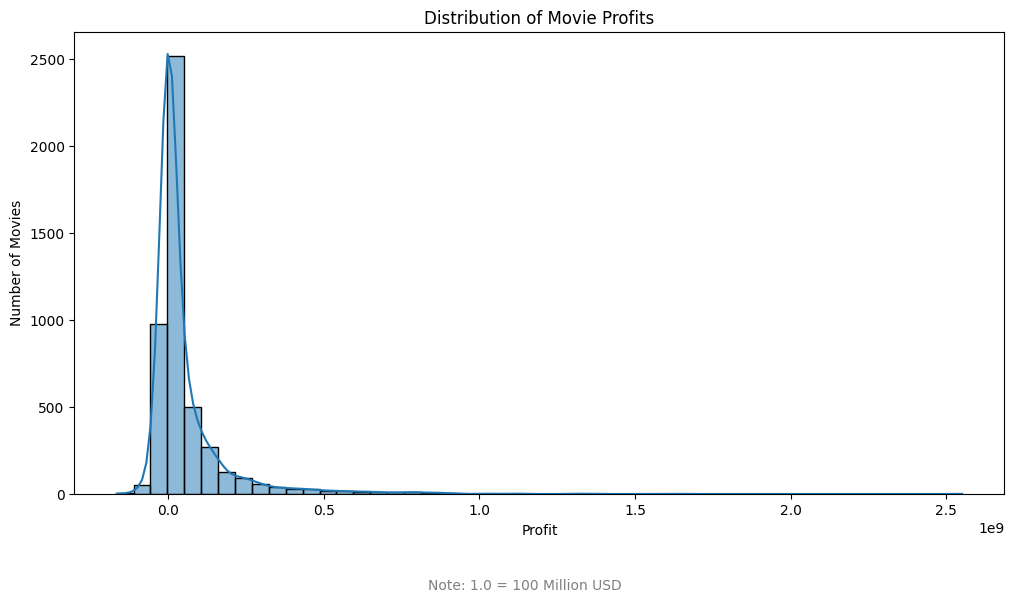

In [ ]:
plt.figure(figsize=(12,6))
sns.histplot(df['profit'], bins=50, kde=True)
plt.title('Distribution of Movie Profits')
plt.xlabel('Profit')
plt.ylabel('Number of Movies')
plt.figtext(0.5, -0.05, 'Note: 1.0 = 100 Million USD', ha='center', fontsize=10, color='gray')
plt.show()

In [ ]:
df.to_csv('movies_cleaned.csv', index=False)

In [ ]:
from google.colab import files
files.download('movies_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

My conclusion is movie producers are messing up big time by not doing adventure movies anymore. With the recent worldwide phenomenon of production companies constantly trying to use nostalgia as a means to make more product, you would think they would have the incentive to bring back adventure movies like The Mummy, Journey to the Center of the Earth, Pirates of the Carribean. Adventure movies make up for the 4 quadrants of moviegoers, and even families, the most profitable quadrant.